In [ ]:
%pip install -q datasets pandas pillow matplotlib scikit-learn

In [ ]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from datasets import load_dataset
from sklearn.model_selection import train_test_split

from google.colab import drive

BASE_DIR = "/content/gdrive/MyDrive/SkinCare_AI/ACNE04"
IMAGE_DIR = os.path.join(BASE_DIR, "images")
SPLIT_DIR = os.path.join(BASE_DIR, "splits")
ANNOTATIONS_PATH = os.path.join(BASE_DIR, "annotations.csv")

print("Project folder:", BASE_DIR)

Project folder: /content/gdrive/MyDrive/SkinCare_AI/ACNE04


In [ ]:
from google.colab import drive
import os

mount_path = "/content/gdrive"

os.makedirs(mount_path, exist_ok=True)
drive.mount(mount_path)

os.makedirs(IMAGE_DIR, exist_ok=True)
os.makedirs(SPLIT_DIR, exist_ok=True)

print("Google Drive mounted successfully!")
print("Project folder:", BASE_DIR)

Mounted at /content/gdrive
Google Drive mounted successfully!
Project folder: /content/gdrive/MyDrive/SkinCare_AI/ACNE04


In [ ]:
print("Loading ACNE04 dataset...")
dataset = load_dataset("Layered-Labs/ACNE04")
data = dataset["train"]

print(dataset)
print("Total images:", len(data))
print("Available columns:", data.column_names)

Loading ACNE04 dataset...


README.md:   0%|          | 0.00/8.60k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  415MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  410MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  305MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1457 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'file_name', 'level', 'severity', 'lesion_count_label', 'num_lesions_annotated', 'lesion_boxes', 'split', 'fold_0_split', 'fold_1_split', 'fold_2_split', 'fold_3_split', 'fold_4_split'],
        num_rows: 1457
    })
})
Total images: 1457
Available columns: ['image', 'file_name', 'level', 'severity', 'lesion_count_label', 'num_lesions_annotated', 'lesion_boxes', 'split', 'fold_0_split', 'fold_1_split', 'fold_2_split', 'fold_3_split', 'fold_4_split']


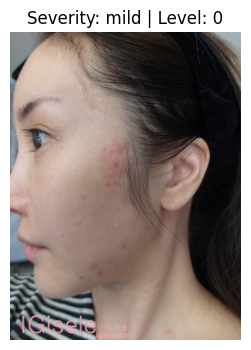

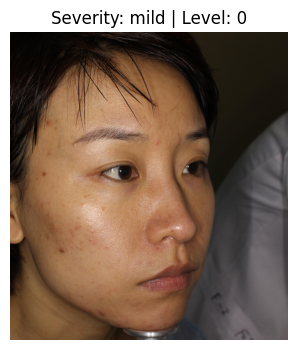

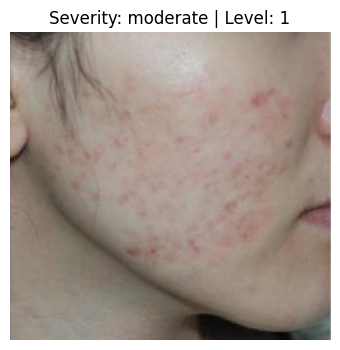

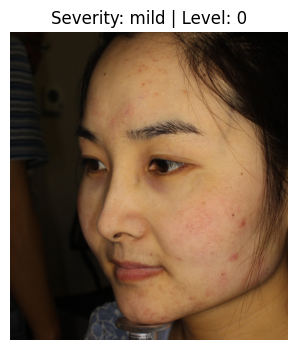

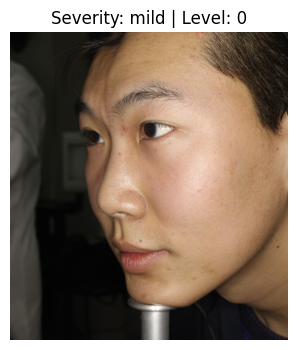

In [ ]:
for i in range(min(5, len(data))):
    sample = data[i]

    plt.figure(figsize=(5, 4))
    plt.imshow(sample["image"])
    plt.title(f"Severity: {sample['severity']} | Level: {sample['level']}")
    plt.axis("off")
    plt.show()

In [ ]:
records = []

for sample in data:
    filename = sample["file_name"]
    image_path = os.path.join(IMAGE_DIR, filename)

    # Avoid rewriting image files when rerunning this cell
    if not os.path.exists(image_path):
        sample["image"].save(image_path)

    records.append({
        "filename": filename,
        "severity": sample["severity"],
        "level": sample["level"],
        "lesion_count": sample["num_lesions_annotated"],
        "lesion_boxes": json.dumps(sample["lesion_boxes"]),
        "split": sample["split"],
        "image_path": image_path
    })

df = pd.DataFrame(records)
df.to_csv(ANNOTATIONS_PATH, index=False)

print("Images in dataset:", len(df))
print("Annotations saved to:", ANNOTATIONS_PATH)
print("Image folder:", IMAGE_DIR)

Images in dataset: 1457
Annotations saved to: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/annotations.csv
Image folder: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/images


In [ ]:
df = pd.read_csv(ANNOTATIONS_PATH)

required_columns = {
    "filename", "severity", "level", "lesion_count",
    "lesion_boxes", "split", "image_path"
}
missing_columns = required_columns - set(df.columns)
assert not missing_columns, f"Missing columns: {missing_columns}"

missing_images = df.loc[~df["image_path"].map(os.path.exists), "filename"].tolist()

valid_images = 0
invalid_images = []

for image_path in df["image_path"]:
    try:
        with Image.open(image_path) as img:
            img.verify()
        valid_images += 1
    except Exception:
        invalid_images.append(image_path)

print("Total annotation records:", len(df))
print("Valid images:", valid_images)
print("Missing image files:", len(missing_images))
print("Invalid image files:", len(invalid_images))
print("Missing CSV values:")
display(df.isnull().sum().to_frame("missing_values"))

assert not missing_images, "Some image files are missing."
assert not invalid_images, "Some image files are invalid."

Total annotation records: 1457
Valid images: 1457
Missing image files: 0
Invalid image files: 0
Missing CSV values:


,missing_values
filename,0
severity,0
level,0
lesion_count,0
lesion_boxes,0
split,0
image_path,0


Severity distribution:


,image_count
severity,
mild,513
moderate,633
severe,182
very_severe,129


Original split distribution:


,image_count
split,
train,1165
test,292


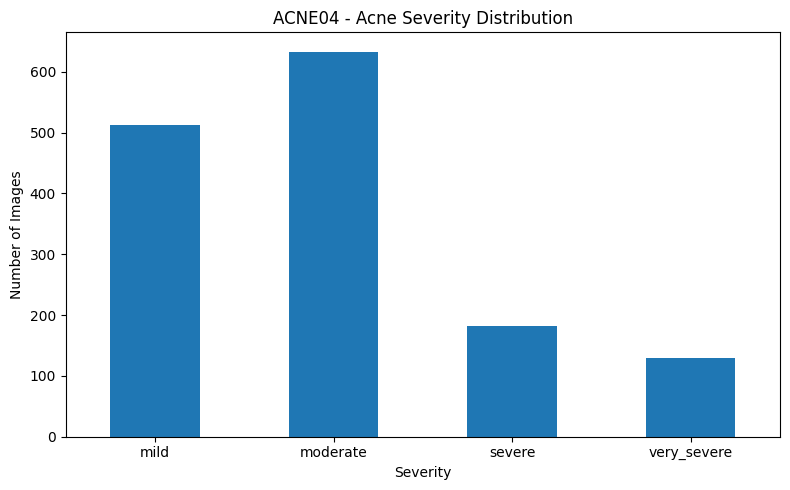

In [ ]:
print("Severity distribution:")
display(df["severity"].value_counts().sort_index().to_frame("image_count"))

print("Original split distribution:")
display(df["split"].value_counts().to_frame("image_count"))

severity_counts = df["severity"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
severity_counts.plot(kind="bar")
plt.title("ACNE04 - Acne Severity Distribution")
plt.xlabel("Severity")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
annotation_issues = []

for _, row in df.iterrows():
    try:
        boxes = json.loads(row["lesion_boxes"])

        keys = ["xmin", "ymin", "xmax", "ymax"]
        if not all(key in boxes for key in keys):
            annotation_issues.append((row["filename"], "Missing coordinate key"))
            continue

        lengths = [len(boxes[key]) for key in keys]
        if len(set(lengths)) != 1:
            annotation_issues.append((row["filename"], "Coordinate arrays have different lengths"))
            continue

        box_count = lengths[0]
        if box_count != int(row["lesion_count"]):
            annotation_issues.append((row["filename"], "Stored lesion count differs from box count"))
            continue

        with Image.open(row["image_path"]) as img:
            width, height = img.size

        for i in range(box_count):
            xmin, ymin = boxes["xmin"][i], boxes["ymin"][i]
            xmax, ymax = boxes["xmax"][i], boxes["ymax"][i]

            if not (0 <= xmin < xmax <= width and 0 <= ymin < ymax <= height):
                annotation_issues.append((row["filename"], f"Invalid/out-of-bounds box at index {i}"))
                break

    except Exception as exc:
        annotation_issues.append((row["filename"], f"Could not parse annotation: {exc}"))

print("Images checked:", len(df))
print("Images with annotation structure/coordinate issues:", len(annotation_issues))

if annotation_issues:
    display(pd.DataFrame(annotation_issues, columns=["filename", "issue"]).head(30))
else:
    print("All stored box arrays, counts and coordinate bounds passed these checks.")

print("\nNote: This checks annotation structure and coordinate validity, not whether every visible acne lesion was labelled.")

Images checked: 1457
Images with annotation structure/coordinate issues: 0
All stored box arrays, counts and coordinate bounds passed these checks.

Note: This checks annotation structure and coordinate validity, not whether every visible acne lesion was labelled.


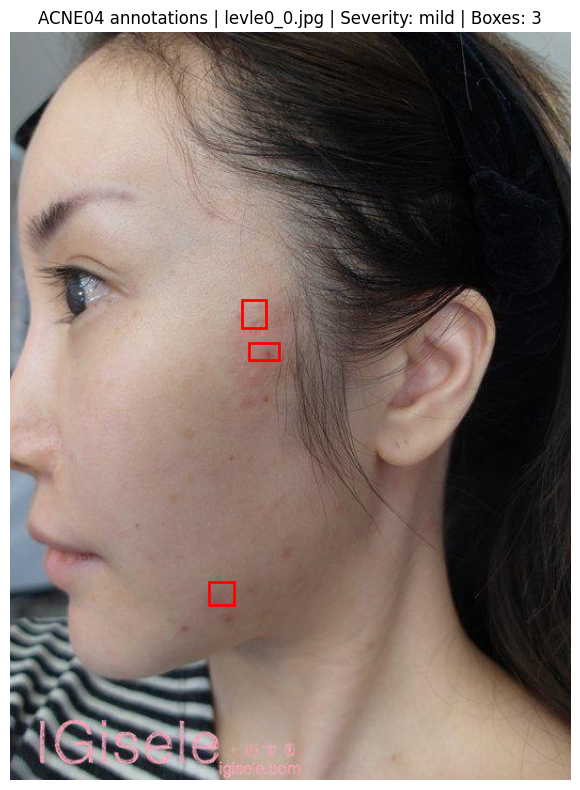

Image dimensions (width, height): (525, 700)
Stored lesion count: 3
Number of bounding boxes: 3


In [ ]:
image_index = 0  # Change this number to inspect another image

row = df.iloc[image_index]
image = Image.open(row["image_path"]).convert("RGB")
boxes = json.loads(row["lesion_boxes"])

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image)

for i in range(len(boxes["xmin"])):
    xmin = boxes["xmin"][i]
    ymin = boxes["ymin"][i]
    xmax = boxes["xmax"][i]
    ymax = boxes["ymax"][i]

    rectangle = plt.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )
    ax.add_patch(rectangle)

ax.set_title(
    f"ACNE04 annotations | {row['filename']} | "
    f"Severity: {row['severity']} | Boxes: {len(boxes['xmin'])}"
)
ax.axis("off")
plt.tight_layout()
plt.show()

print("Image dimensions (width, height):", image.size)
print("Stored lesion count:", row["lesion_count"])
print("Number of bounding boxes:", len(boxes["xmin"]))

In [ ]:
# Keep the original test partition untouched
train_val = df[df["split"] == "train"].copy()
test_data = df[df["split"] == "test"].copy()

# Split only the original training partition into train and validation
train_data, val_data = train_test_split(
    train_val,
    test_size=0.1765,
    random_state=42,
    stratify=train_val["severity"]
)

# Confirm there is no overlap between partitions
train_files = set(train_data["filename"])
val_files = set(val_data["filename"])
test_files = set(test_data["filename"])

assert train_files.isdisjoint(val_files)
assert train_files.isdisjoint(test_files)
assert val_files.isdisjoint(test_files)
assert len(train_data) + len(val_data) + len(test_data) == len(df)

train_data.to_csv(os.path.join(SPLIT_DIR, "train.csv"), index=False)
val_data.to_csv(os.path.join(SPLIT_DIR, "validation.csv"), index=False)
test_data.to_csv(os.path.join(SPLIT_DIR, "test.csv"), index=False)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))
print("Total images:", len(train_data) + len(val_data) + len(test_data))

Training images: 959
Validation images: 206
Testing images: 292
Total images: 1457


In [ ]:
for split_name, split_df in [
    ("TRAINING", train_data),
    ("VALIDATION", val_data),
    ("TESTING", test_data)
]:
    print(f"\n{split_name} SET ({len(split_df)} images)")
    display(split_df["severity"].value_counts().sort_index().to_frame("image_count"))


TRAINING SET (959 images)


,image_count
severity,
mild,337
moderate,417
severe,120
very_severe,85



VALIDATION SET (206 images)


,image_count
severity,
mild,73
moderate,89
severe,26
very_severe,18



TESTING SET (292 images)


,image_count
severity,
mild,103
moderate,127
severe,36
very_severe,26
